# Object Detection in Football: Accuracy and Inference Speed

**Dataset:** Roboflow Football Players Detection v13. The validation set contains 49 football frames with 45 annotated balls and 1,129 annotated people. Players, goalkeepers and referees are evaluated together as the `person` class.

**Objective:** Investigate how YOLO26 model size affects detection quality and inference speed for balls and people in football footage.

**Approach:**

1. Compare four pretrained YOLO26 variants (nano, small, medium and large) on the same validation frames.
2. Use a fixed input size of 1280 × 1280 pixels and a confidence threshold of 0.25 for all models.
3. Evaluate ball and person detections separately, inspect false positives and false negatives, and assess whether any model meets a real-time target of 25 FPS.

**Metrics:** Precision, recall and F1 score per class, using an IoU threshold of 0.50 to match predictions to annotations. Speed is measured as mean inference time per frame (ms) and inference throughput (FPS).

# Imports

In [1]:
from pathlib import Path
from time import perf_counter
from PIL import Image, ImageDraw
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Load Dataset

In [2]:
dataset_dir = Path("data/football-players-detection.v13i.yolo26")

if not (dataset_dir / "data.yaml").is_file():
    raise FileNotFoundError(f"File not found at {dataset_dir}")

for split in ("train","valid" ,"test"):
    image_dir = dataset_dir / split / "images"
    label_dir = dataset_dir / split / "labels"

    images = list(image_dir.glob("*.jpg"))
    labels = list(label_dir.glob("*.txt"))

    print(f"{split}: {len(images)} images, {len(labels)} marked files")


train: 298 images, 298 marked files
valid: 49 images, 49 marked files
test: 25 images, 25 marked files


# Example

yellow = ball | orange = goalkeeper | green = player | cyan = referee


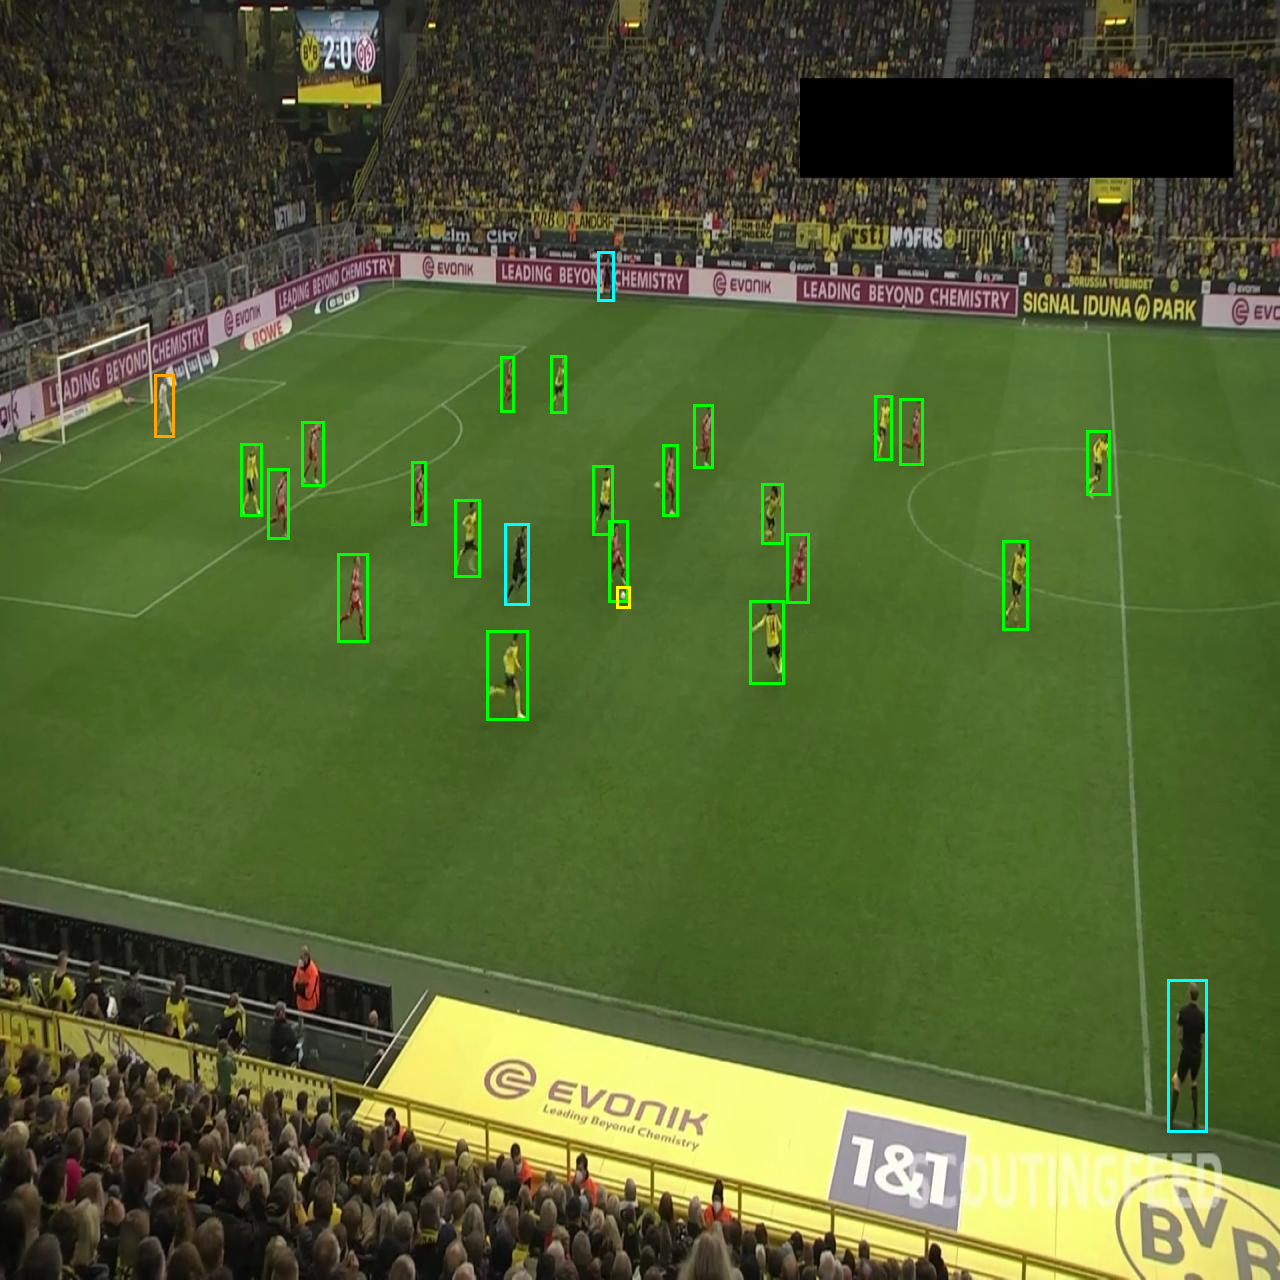

In [3]:
frame_name = "4b770a_3_7_png.rf.f056221cfdb2c5519bb3bf9902a2ac4b"
image_path = dataset_dir / "valid" / "images" / f"{frame_name}.jpg"
label_path = dataset_dir / "valid" / "labels" / f"{frame_name}.txt"

image = Image.open(image_path).convert("RGB")
width, height = image.size
draw = ImageDraw.Draw(image)

colors = {0: "yellow", 1: "orange", 2: "lime", 3: "cyan"}

for line in label_path.read_text().splitlines():
    class_id, center_x, center_y, box_w, box_h = line.split()
    class_id = int(class_id)

    center_x = float(center_x) * width
    center_y = float(center_y) * height
    box_w = float(box_w) * width
    box_h = float(box_h) * height

    left = center_x - box_w / 2
    top = center_y - box_h / 2
    right = center_x + box_w / 2
    bottom = center_y + box_h / 2

    draw.rectangle((left, top, right, bottom), outline=colors[class_id], width=3)

print("yellow = ball | orange = goalkeeper | green = player | cyan = referee")
display(image)

# Detection Settings

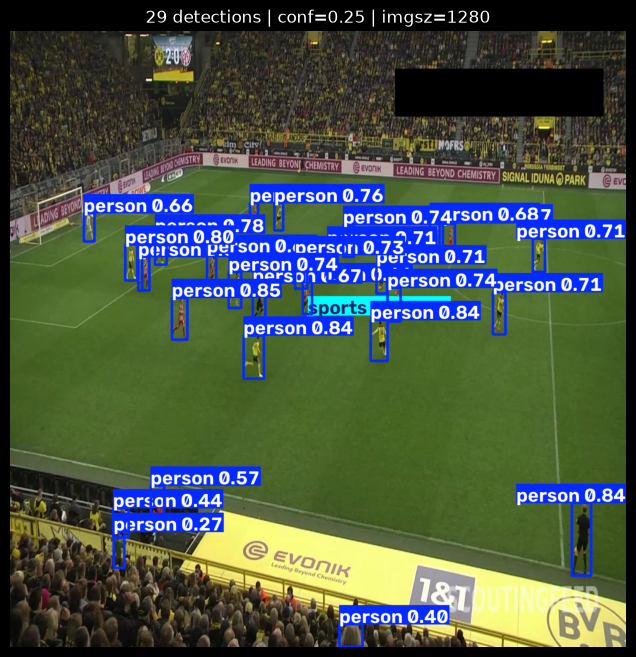

,class,confidence,x1,y1,x2,y2
0,person,0.85,336.329987,554.400024,368.440002,641.309998
1,person,0.84,1167.680054,980.619995,1207.189941,1131.810059
2,person,0.84,485.739990,632.099976,527.239990,722.210022
3,person,0.84,749.159973,600.700012,784.840027,685.309998
4,person,0.80,239.830002,443.700012,264.299988,518.159973
5,person,0.78,301.149994,420.739990,325.279999,485.510010
6,person,0.76,549.739990,357.399994,567.570007,414.309998
7,person,0.74,454.049988,500.480011,480.660004,575.500000
8,person,0.74,784.840027,533.359985,811.419983,603.530029
9,person,0.74,692.919983,402.869995,714.030029,469.529999


In [4]:
model = YOLO("yolo26l.pt")
conf = 0.25
imgsz = 1280
iou = 0.70
classes = None
max_det = 300

frame_result = model(
    str(image_path),
    conf=conf,
    imgsz=imgsz,
    iou=iou,
    classes=classes,
    max_det=max_det,
    verbose=False,
)[0]

plt.figure(figsize=(12, 8))
plt.imshow(frame_result.plot()[:, :, ::-1])
plt.title(f"{len(frame_result.boxes)} detections | conf={conf} | imgsz={imgsz}")
plt.axis("off")
plt.show()

boxes = frame_result.boxes
detections = pd.DataFrame(boxes.xyxy.cpu().numpy(), columns=["x1", "y1", "x2", "y2"])
detections["class_id"] = boxes.cls.int().tolist()
detections["class"] = detections["class_id"].map(model.names)
detections["confidence"] = boxes.conf.tolist()

display(detections[["class", "confidence", "x1", "y1", "x2", "y2"]].round(2))

# Ball detection on the validation set

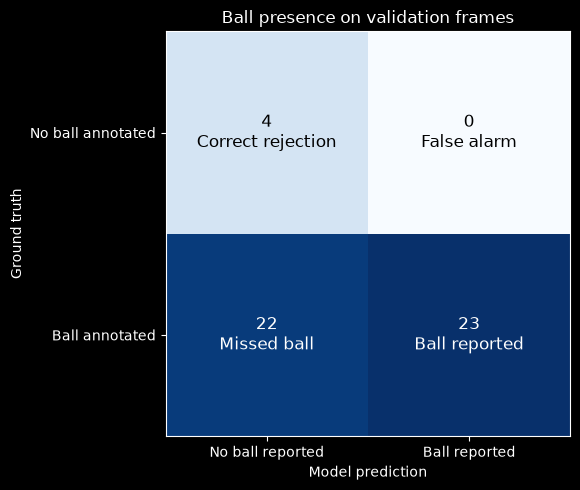

In [5]:
valid_dir = dataset_dir / "valid"
rows = []

for frame_path in sorted((valid_dir / "images").glob("*.jpg")):
    annotation_path = valid_dir / "labels" / f"{frame_path.stem}.txt"
    lines = annotation_path.read_text().splitlines()
    ball_annotated = any(line.split()[0] == "0" for line in lines if line.strip())

    prediction = model(str(frame_path), imgsz=imgsz, conf=conf, classes=[32], verbose=False)[0]
    ball_predicted = len(prediction.boxes) > 0

    rows.append({
        "frame": frame_path.name,
        "ball_annotated": ball_annotated,
        "ball_prediction": ball_predicted,
    })

ball_results = pd.DataFrame(rows)
matrix = pd.crosstab(
    ball_results["ball_annotated"],
    ball_results["ball_prediction"],
).reindex(index=[False, True], columns=[False, True], fill_value=0)

cell_labels = [
    ["Correct rejection", "False alarm"],
    ["Missed ball", "Ball reported"],
]

fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(matrix, cmap="Blues", vmin=0)

ax.set_title("Ball presence on validation frames")
ax.set_xlabel("Model prediction")
ax.set_ylabel("Ground truth")
ax.set_xticks([0, 1], labels=["No ball reported", "Ball reported"])
ax.set_yticks([0, 1], labels=["No ball annotated", "Ball annotated"])

max_count = matrix.to_numpy().max()

for row in range(2):
    for col in range(2):
        count = matrix.iloc[row, col]
        ax.text(
            col, row,
            f"{count}\n{cell_labels[row][col]}",
            ha="center", va="center",
            color="white" if count > max_count / 2 else "black",
            fontsize=12,
        )

plt.tight_layout()
plt.show()

# Model size comparison

In [6]:
model_sizes = ["n", "s", "m", "l"]
comparison = {}

for size in model_sizes:
    detector = YOLO(f"yolo26{size}.pt")
    detector(str(image_path), imgsz=1280, conf=0.25, classes=[0, 32], verbose=False)
    comparison[size] = detector(
        str(image_path),
        imgsz=1280,
        conf=0.25,
        classes=[0, 32],
        verbose=False,
    )[0]

    print(f"YOLO26{size}: {len(comparison[size].boxes)} detections")

YOLO26n: 29 detections
YOLO26s: 25 detections
YOLO26m: 30 detections
YOLO26l: 28 detections


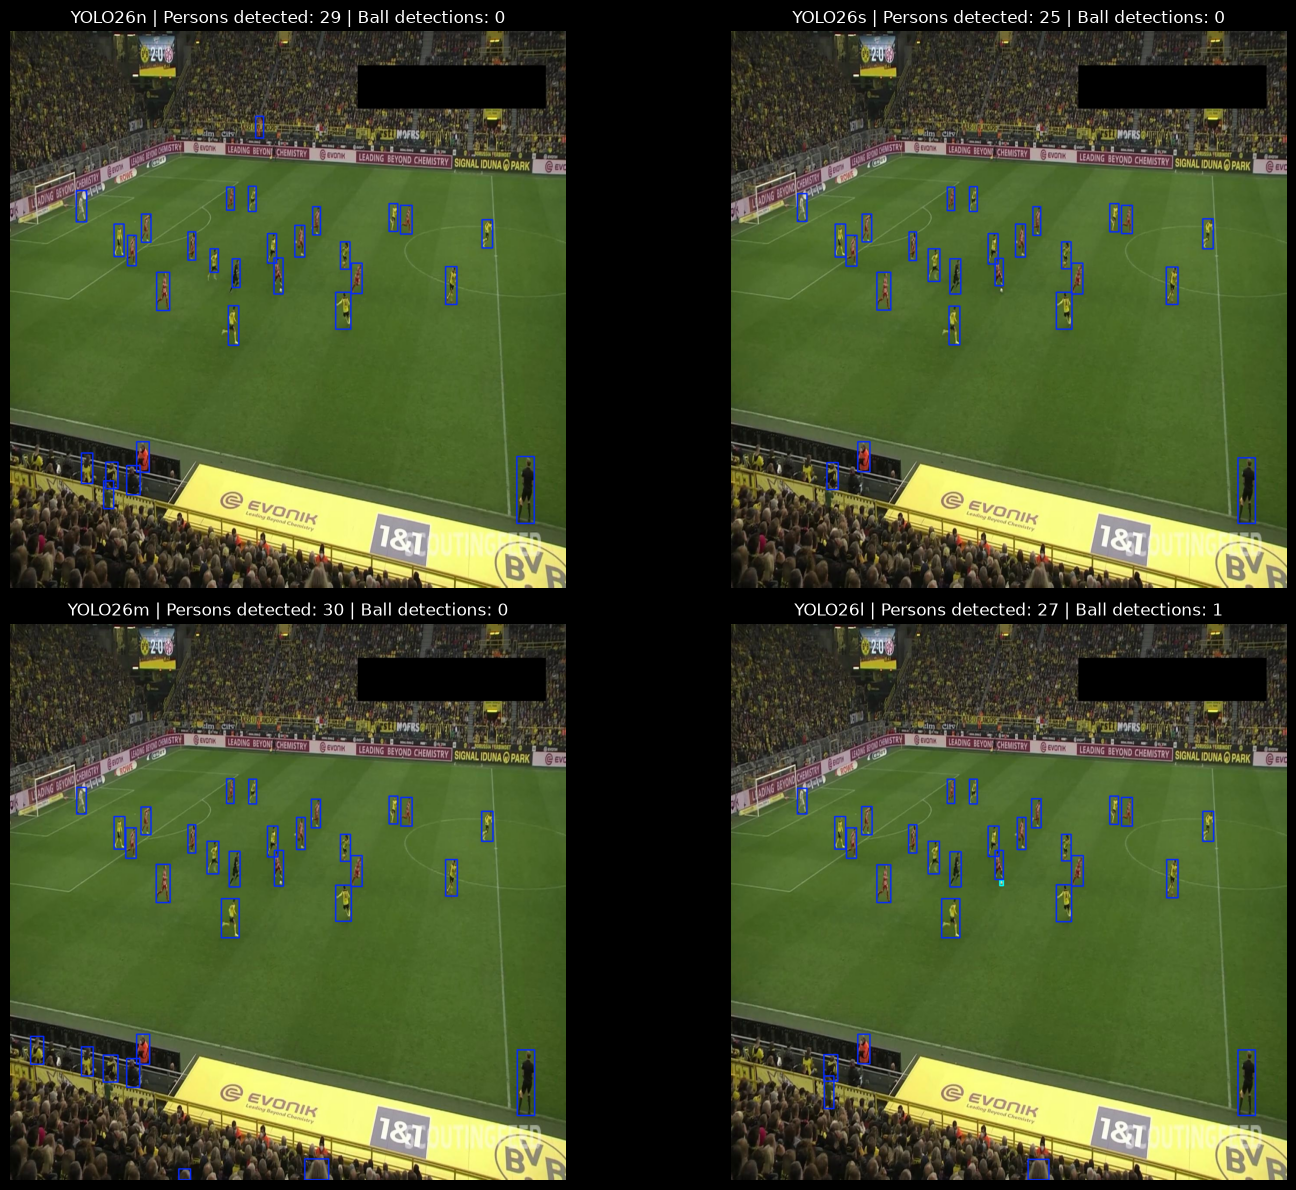

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, size in zip(axes.flat, model_sizes):
    result = comparison[size]
    annotated_frame = result.plot(labels=False, conf=False, line_width=2)
    ax.imshow(annotated_frame[:, :, ::-1])

    class_ids = result.boxes.cls.int().tolist()
    person_count = class_ids.count(0)   # person
    ball_count = class_ids.count(32)    # sports ball

    ax.set_title(f"YOLO26{size} | Persons detected: {person_count} | Ball detections: {ball_count}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Ball Bounding Box evaluation

In [8]:
def calculate_iou(box_a, box_b):

    left_a, top_a, right_a, bottom_a = box_a
    left_b, top_b, right_b, bottom_b = box_b

    overlap_width = max(0, min(right_a, right_b) - max(left_a, left_b))
    overlap_height = max(0, min(bottom_a, bottom_b) - max(top_a, top_b))
    intersection = overlap_width * overlap_height

    area_a = (right_a - left_a) * (bottom_a - top_a)
    area_b = (right_b - left_b) * (bottom_b - top_b)
    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0


result_l = comparison["l"]
height, width = result_l.orig_shape

label_lines = label_path.read_text().splitlines()
ball_line = next(line for line in label_lines if line.startswith("0 "))
center_x, center_y, box_w, box_h = map(float, ball_line.split()[1:])

ground_truth_box = (
    (center_x - box_w / 2) * width,
    (center_y - box_h / 2) * height,
    (center_x + box_w / 2) * width,
    (center_y + box_h / 2) * height,
)

ball_mask = result_l.boxes.cls == 32
predicted_box = result_l.boxes.xyxy[ball_mask][0].tolist()

ball_iou = calculate_iou(predicted_box, ground_truth_box)

print("Predicted box:", [round(value, 1) for value in predicted_box])
print("Ground-truth box:", [round(value, 1) for value in ground_truth_box])
print(f"IoU: {ball_iou:.3f}")
print("Correct detection at IoU 0.50:", ball_iou >= 0.50)


Predicted box: [619.8, 590.7, 627.1, 602.9]
Ground-truth box: [616.0, 586.0, 630.0, 608.0]
IoU: 0.291
Correct detection at IoU 0.50: False


In [9]:
def match_detections(predicted_boxes, ground_truth_boxes, iou_threshold=0.50):
    remaining_boxes = list(ground_truth_boxes)
    matched_ious = []

    for predicted_box in predicted_boxes:
        if not remaining_boxes:
            break

        overlaps = [calculate_iou(predicted_box, box) for box in remaining_boxes]
        best_iou = max(overlaps)

        if best_iou >= iou_threshold:
            best_index = overlaps.index(best_iou)
            remaining_boxes.pop(best_index)
            matched_ious.append(best_iou)

    tp = len(matched_ious)
    fp = len(predicted_boxes) - tp
    fn = len(remaining_boxes)

    return tp, fp, fn

tp, fp, fn = match_detections([predicted_box], [ground_truth_box])
print(f"TP: {tp}, FP: {fp}, FN: {fn}")

TP: 0, FP: 1, FN: 1


# Ball precrison and recall on the validation set

In [10]:
detector = YOLO("yolo26l.pt")
valid_dir = dataset_dir / "valid"

total_tp = 0
total_fp = 0
total_fn = 0

for frame_path in sorted((valid_dir / "images").glob("*.jpg")):
    result = detector(str(frame_path), imgsz=1280, conf=0.25,
                      classes=[32], verbose=False)[0]
    order = result.boxes.conf.argsort(descending=True)
    predicted_boxes = result.boxes.xyxy[order].tolist()

    height, width = result.orig_shape
    label_file = valid_dir / "labels" / f"{frame_path.stem}.txt"
    ground_truth_boxes = []

    for line in label_file.read_text().splitlines():
        class_id, cx, cy, w, h = line.split()
        if class_id == "0":
            cx, cy, w, h = map(float, (cx, cy, w, h))
            ground_truth_boxes.append((
                (cx - w / 2) * width,
                (cy - h / 2) * height,
                (cx + w / 2) * width,
                (cy + h / 2) * height,
            ))

    tp, fp, fn = match_detections(predicted_boxes, ground_truth_boxes)
    total_tp += tp
    total_fp += fp
    total_fn += fn

precision = total_tp / (total_tp + total_fp) if total_tp + total_fp else 0.0
recall = total_tp / (total_tp + total_fn) if total_tp + total_fn else 0.0

print(f"TP: {total_tp} | FP: {total_fp} | FN: {total_fn}")
print(f"Ball precision: {precision:.1%}")
print(f"Ball recall:    {recall:.1%}")

TP: 13 | FP: 13 | FN: 32
Ball precision: 50.0%
Ball recall:    28.9%


# Person precision and recall on the validation set

In [11]:
detector = YOLO("yolo26l.pt")
valid_dir = dataset_dir / "valid"

person_tp = 0
person_fp = 0
person_fn = 0

for frame_path in sorted((valid_dir / "images").glob("*.jpg")):
    result = detector(
        str(frame_path),
        imgsz=1280,
        conf=0.25,
        classes=[0],
        verbose=False,
    )[0]

    order = result.boxes.conf.argsort(descending=True)
    predicted_boxes = result.boxes.xyxy[order].tolist()

    height, width = result.orig_shape
    label_file = valid_dir / "labels" / f"{frame_path.stem}.txt"
    ground_truth_boxes = []

    for line in label_file.read_text().splitlines():
        class_id, cx, cy, w, h = line.split()

        if class_id in ("1", "2", "3"):
            cx, cy, w, h = map(float, (cx, cy, w, h))
            ground_truth_boxes.append((
                (cx - w / 2) * width,
                (cy - h / 2) * height,
                (cx + w / 2) * width,
                (cy + h / 2) * height,
            ))

    tp, fp, fn = match_detections(
        predicted_boxes, ground_truth_boxes, iou_threshold=0.50
    )
    person_tp += tp
    person_fp += fp
    person_fn += fn

predicted_people = person_tp + person_fp
annotated_people = person_tp + person_fn

person_precision = person_tp / predicted_people if predicted_people else 0.0
person_recall = person_tp / annotated_people if annotated_people else 0.0

print(f"TP: {person_tp} | FP: {person_fp} | FN: {person_fn}")
print(f"Person precision: {person_precision:.1%}")
print(f"Person recall:    {person_recall:.1%}")
print(f"Annotated people: {annotated_people}")

TP: 1062 | FP: 305 | FN: 67
Person precision: 77.7%
Person recall:    94.1%
Annotated people: 1129


# Detection quality and inference speed by model size

In [12]:
def evaluate_models(settings):
    """Evaluate the four YOLO26 variants using the same prediction settings."""
    valid_dir = dataset_dir / "valid"
    frame_paths = sorted((valid_dir / "images").glob("*.jpg"))

    if not frame_paths:
        raise FileNotFoundError(f"No validation images found in {valid_dir}")

    model_classes = {"ball": 32, "person": 0}

    dataset_classes = {
        "0": "ball",
        "1": "person",  # goalkeeper
        "2": "person",  # player
        "3": "person",  # referee
    }

    summary_rows = []

    for size in ["n", "s", "m", "l"]:
        model_name = f"yolo26{size}"
        detector = YOLO(f"{model_name}.pt")
        print(f"Evaluating {model_name} at {settings['imgsz']} px...")

        for _ in range(3):
            detector(str(frame_paths[0]), **settings)

        totals = {
            "ball": {"TP": 0, "FP": 0, "FN": 0},
            "person": {"TP": 0, "FP": 0, "FN": 0},
        }
        inference_times = []

        for frame_path in frame_paths:
            result = detector(str(frame_path), **settings)[0]
            inference_times.append(result.speed["inference"])

            height, width = result.orig_shape
            label_file = valid_dir / "labels" / f"{frame_path.stem}.txt"
            ground_truth = {"ball": [], "person": []}

            for line in label_file.read_text().splitlines():
                class_id, cx, cy, w, h = line.split()
                cx, cy, w, h = map(float, (cx, cy, w, h))

                box = (
                    (cx - w / 2) * width,
                    (cy - h / 2) * height,
                    (cx + w / 2) * width,
                    (cy + h / 2) * height,
                )
                class_name = dataset_classes[class_id]
                ground_truth[class_name].append(box)

            for class_name, class_id in model_classes.items():
                boxes = result.boxes[result.boxes.cls == class_id]
                order = boxes.conf.argsort(descending=True)
                predicted_boxes = boxes.xyxy[order].tolist()

                tp, fp, fn = match_detections(
                    predicted_boxes, ground_truth[class_name], iou_threshold=0.50
                )
                totals[class_name]["TP"] += tp
                totals[class_name]["FP"] += fp
                totals[class_name]["FN"] += fn

        row = {"model": model_name, "imgsz": settings["imgsz"], "conf": settings["conf"]}

        for class_name, counts in totals.items():
            tp = counts["TP"]
            fp = counts["FP"]
            fn = counts["FN"]

            row[f"{class_name} precision (%)"] = 100 * tp / (tp + fp) if tp + fp else 0.0
            row[f"{class_name} recall (%)"] = 100 * tp / (tp + fn) if tp + fn else 0.0
            row[f"{class_name} F1 (%)"] = 100 * 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0

        mean_ms = sum(inference_times) / len(inference_times)
        row["inference ms/frame"] = mean_ms
        row["inference FPS"] = 1000 / mean_ms
        summary_rows.append(row)

    return pd.DataFrame(summary_rows)

# 1280 Pixels


In [13]:
baseline_settings = dict(imgsz=1280, conf=0.25, classes=[0, 32], verbose=False)
results_1280 = evaluate_models(baseline_settings)
display(results_1280.round(2))

Evaluating yolo26n at 1280 px...
Evaluating yolo26s at 1280 px...
Evaluating yolo26m at 1280 px...
Evaluating yolo26l at 1280 px...


,model,imgsz,conf,ball precision (%),ball recall (%),ball F1 (%),person precision (%),person recall (%),person F1 (%),inference ms/frame,inference FPS
0,yolo26n,1280,0.25,0.00,0.00,0.00,73.16,72.19,72.67,146.92,6.81
1,yolo26s,1280,0.25,41.18,15.56,22.58,79.74,92.38,85.60,319.19,3.13
2,yolo26m,1280,0.25,56.25,20.00,29.51,74.89,93.53,83.18,687.92,1.45
3,yolo26l,1280,0.25,50.00,28.89,36.62,77.69,94.07,85.10,873.59,1.14


# 640 Pixels


In [16]:
settings = dict(imgsz=640, conf=0.25, classes=[0, 32], verbose=False)
results_640 = evaluate_models(settings)
display(results_640.round(2))

Evaluating yolo26n at 640 px...
Evaluating yolo26s at 640 px...
Evaluating yolo26m at 640 px...
Evaluating yolo26l at 640 px...


,model,imgsz,conf,ball precision (%),ball recall (%),ball F1 (%),person precision (%),person recall (%),person F1 (%),inference ms/frame,inference FPS
0,yolo26n,640,0.25,66.67,4.44,8.33,82.72,67.40,74.28,37.09,26.96
1,yolo26s,640,0.25,100.00,4.44,8.51,87.23,82.29,84.69,69.60,14.37
2,yolo26m,640,0.25,71.43,11.11,19.23,86.39,87.69,87.03,147.91,6.76
3,yolo26l,640,0.25,83.33,11.11,19.61,87.78,83.97,85.83,200.07,5.00


# 1920 Pixels

In [17]:
settings = dict(imgsz=1920, conf=0.25, classes=[0, 32], verbose=False)
results_1920 = evaluate_models(settings)
display(results_1920.round(2))

Evaluating yolo26n at 1920 px...
Evaluating yolo26s at 1920 px...
Evaluating yolo26m at 1920 px...
Evaluating yolo26l at 1920 px...


,model,imgsz,conf,ball precision (%),ball recall (%),ball F1 (%),person precision (%),person recall (%),person F1 (%),inference ms/frame,inference FPS
0,yolo26n,1920,0.25,0.00,0.00,0.00,68.14,60.23,63.94,334.94,2.99
1,yolo26s,1920,0.25,33.33,35.56,34.41,66.50,92.65,77.42,749.41,1.33
2,yolo26m,1920,0.25,39.02,35.56,37.21,63.26,93.18,75.36,1594.76,0.63
3,yolo26l,1920,0.25,37.29,48.89,42.31,66.58,94.77,78.22,2154.40,0.46
